### Cooperation networks over different conditions

In [225]:
import pandas as pd
import json
import seaborn as sns
import numpy as np

import networkx as nx

from pyvis.network import Network

import sys

sys.path.append("../functions/")
import networks

In [226]:
import os

In [227]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [228]:
with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [237]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = media_db[media_db.medium=="M9"].compound.values
compounds = list(compounds)
compounds.remove("glc__D")
m9_compounds = ["M_"+met+"__91__e__93__" for met in compounds]

In [238]:
results_all = {}

for filename in os.listdir("../output/Venturelli2018/results_steadiercom/"):
    
    if filename.endswith(".tsv"):
        name = filename.replace(".tsv","")

        results_all[name] = pd.read_csv(f"../output/Venturelli2018/results_steadiercom/{filename}",sep="\t")

In [239]:
results = pd.concat(results_all).reset_index(drop=True)

results["mass_rate*frequency"] = results["frequency"]*results["mass_rate"]
results = results[~results.compound.isin(m9_compounds)]

### Closeness_centrality (out)

In [276]:
centrality_metrics_SP_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=True,freq_cutoff=0.1)
    centrality_metrics_SP = networks.cooperation_centrality_metrics(network_data,SP_type="out")
    
    centrality_metrics_SP_comm[comm]=centrality_metrics_SP
    

In [277]:
centrality = pd.concat(centrality_metrics_SP_comm)["closeness (1/data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,1.875000,0.923077,2.105263,1.304348,NaN,1.363636,1.132075,0.566038,1.363636,1.188119,1.176471,1.212121
BO-,NaN,1.121495,1.224490,1.428571,0.759494,1.500000,1.016949,0.722892,1.276596,1.276596,1.818182,1.276596
BT-,1.518987,NaN,1.818182,1.304348,0.967742,1.290323,1.052632,0.000000,1.100917,1.237113,1.318681,1.052632
BU-,2.545455,1.000000,NaN,1.673307,1.176471,1.690141,1.100917,0.638298,0.810811,1.481481,2.142857,1.621622
BV-,1.511335,0.810811,1.791045,NaN,0.869565,1.237113,1.016949,0.000000,1.016949,1.142857,1.237113,1.100917
CA-,2.000000,0.937500,1.935484,1.237113,0.764331,1.304348,NaN,0.000000,0.944882,1.271186,1.111111,1.395349
CH-,1.954397,0.909091,1.935484,1.481481,0.784314,NaN,0.882353,0.000000,1.212121,1.421801,1.200000,1.578947
DP-,1.869159,0.833333,1.318681,1.263158,1.000000,1.304348,1.016949,NaN,1.142857,1.224490,1.578947,1.176471
EL-,2.424242,1.395349,1.333333,1.678322,0.524017,1.100917,0.991736,0.000000,NaN,1.621622,2.264151,1.621622
ER-,1.791045,0.967742,1.875000,1.395349,1.071429,1.518987,1.153846,0.641711,1.290323,NaN,1.558442,1.304348


In [278]:
#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

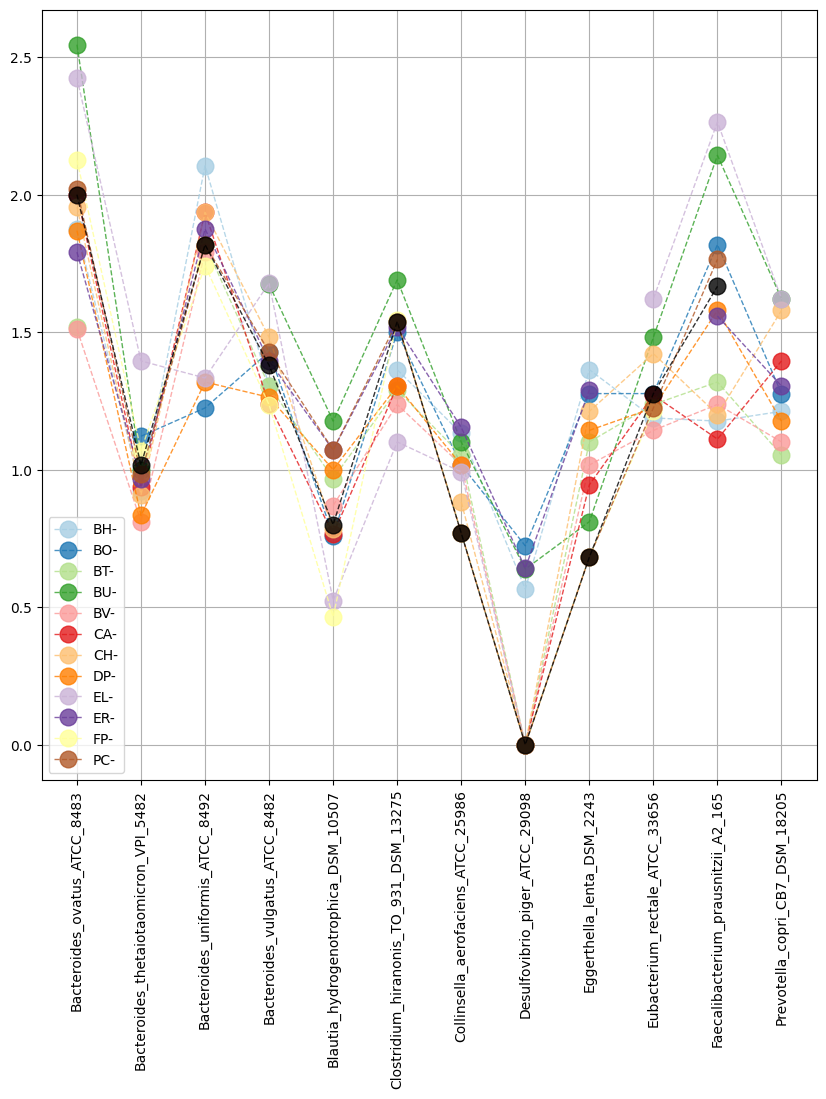

In [279]:

ax = centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired")
centrality_sorted.T["NONE"].plot(ax=ax,color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)

x = centrality_sorted.columns.values
ax.set_xticks(np.arange(len(x)))
labels = ax.set_xticklabels(x,rotation=90)

### Closeness_centrality (in)

In [330]:
centrality_metrics_SP_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=True,freq_cutoff=0.1)
    centrality_metrics_SP = networks.cooperation_centrality_metrics(network_data,SP_type="in")
    
    centrality_metrics_SP_comm[comm]=centrality_metrics_SP
    

In [331]:
centrality = pd.concat(centrality_metrics_SP_comm)["closeness (1/data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,0.869565,1.348315,0.983607,1.165049,NaN,1.428571,1.428571,1.558442,1.111111,1.034483,1.395349,0.909091
BO-,NaN,1.395349,0.705882,1.304348,1.016949,1.363636,1.445783,1.379310,1.188119,1.043478,1.445783,0.882353
BT-,0.796721,NaN,1.092135,1.495385,0.803306,1.331507,1.450746,1.578947,1.143529,0.991837,1.620000,0.790244
BU-,0.937500,1.231672,NaN,1.064639,0.960000,1.411765,1.518987,2.105263,1.224490,1.081081,1.450777,1.304348
BV-,0.736364,1.486239,0.753488,NaN,0.783871,1.388571,1.350000,1.428571,1.117241,0.972000,1.350000,0.689362
CA-,0.796721,1.262338,0.991837,1.034043,0.972000,1.278947,NaN,1.863354,0.867857,0.934615,1.388571,1.034043
CH-,0.747692,1.151659,1.130233,1.171084,0.783871,NaN,1.472727,1.492537,1.495385,0.852632,1.278947,1.278947
DP-,0.816327,1.530612,0.794702,1.474201,0.845070,1.935484,1.538462,NaN,1.212121,1.200000,1.680672,1.263158
EL-,0.852632,1.313514,1.092135,1.028571,0.837931,1.278947,1.705263,1.538462,NaN,0.952941,1.378723,1.130233
ER-,0.821918,1.411765,1.100917,1.445783,0.923077,1.463415,1.395349,1.500000,1.132075,NaN,1.600000,1.165049


In [332]:
#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

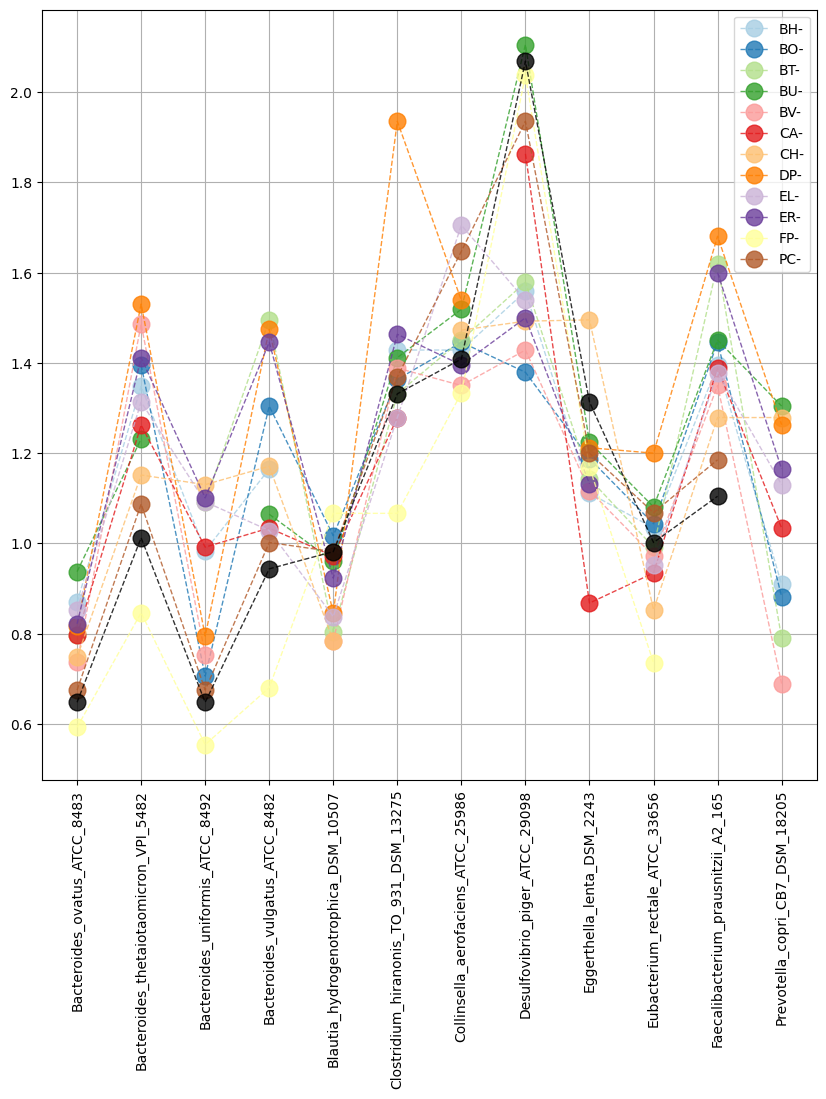

In [333]:

ax = centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired")
centrality_sorted.T["NONE"].plot(ax=ax,color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)

x = centrality_sorted.columns.values
ax.set_xticks(np.arange(len(x)))
labels = ax.set_xticklabels(x,rotation=90)

### Out degree!

In [334]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=True,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

In [335]:
centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,20.0,6.0,23.0,9.0,NaN,15.0,7.0,1.0,12.0,12.0,10.0,8.0
BO-,NaN,10.0,12.0,12.0,4.0,16.0,7.0,3.0,9.0,12.0,19.0,9.0
BT-,16.0,NaN,20.0,10.0,7.0,14.0,9.0,0.0,8.0,12.0,12.0,6.0
BU-,32.0,8.0,NaN,12.0,6.0,18.0,11.0,1.0,5.0,13.0,22.0,10.0
BV-,17.0,6.0,19.0,NaN,4.0,14.0,9.0,0.0,7.0,10.0,12.0,8.0
CA-,21.0,7.0,23.0,7.0,5.0,15.0,NaN,0.0,4.0,16.0,11.0,9.0
CH-,24.0,7.0,21.0,11.0,5.0,NaN,3.0,0.0,9.0,16.0,12.0,11.0
DP-,24.0,6.0,13.0,10.0,5.0,13.0,7.0,NaN,10.0,11.0,18.0,6.0
EL-,34.0,6.0,6.0,11.0,1.0,10.0,8.0,0.0,NaN,14.0,27.0,9.0
ER-,18.0,6.0,20.0,10.0,7.0,15.0,9.0,1.0,10.0,NaN,16.0,8.0


In [336]:
#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

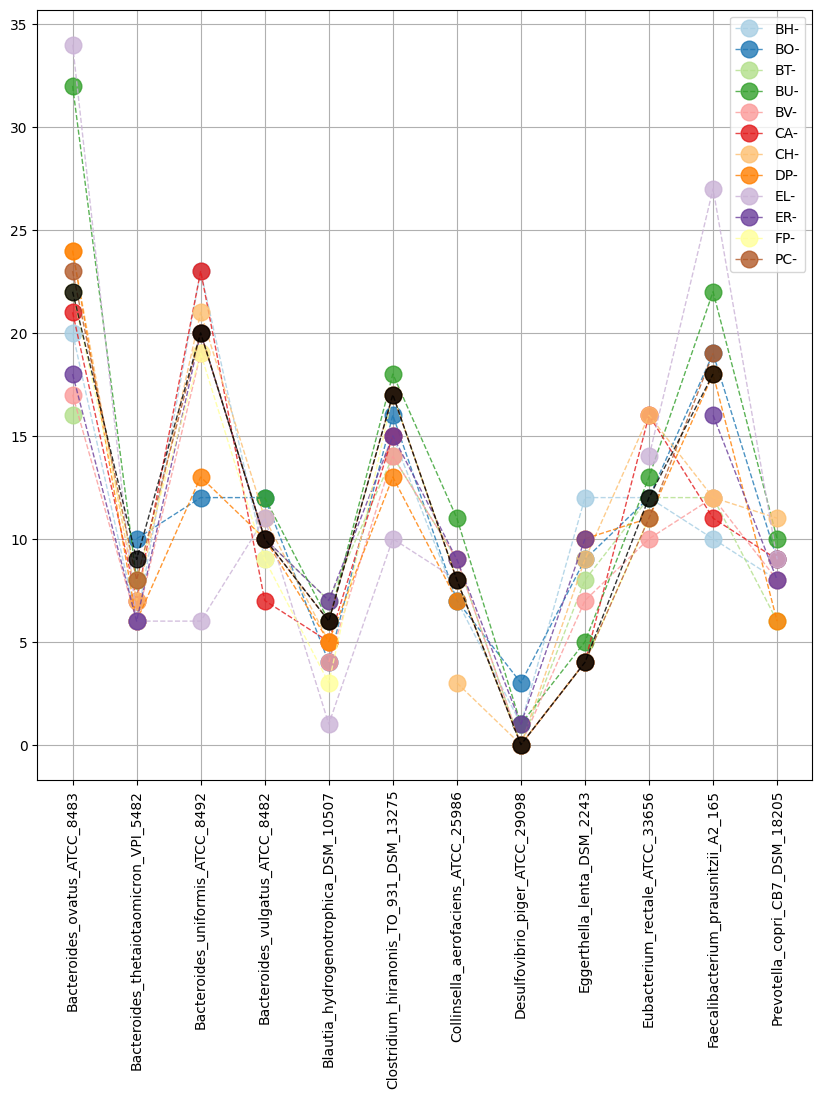

In [337]:

ax = centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired")
centrality_sorted.T["NONE"].plot(ax=ax,color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)

x = centrality_sorted.columns.values
ax.set_xticks(np.arange(len(x)))
labels = ax.set_xticklabels(x,rotation=90)

### In degree!

In [338]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=True,freq_cutoff=0.2)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

In [339]:
centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,4.0,12.0,5.0,7.0,NaN,9.0,5.0,5.0,2.0,3.0,0.0,0.0
BO-,NaN,8.0,3.0,7.0,4.0,8.0,5.0,3.0,3.0,3.0,0.0,NaN
BT-,4.0,NaN,5.0,8.0,2.0,8.0,6.0,4.0,3.0,2.0,1.0,NaN
BU-,2.0,11.0,NaN,5.0,2.0,7.0,5.0,6.0,4.0,3.0,2.0,3.0
BV-,4.0,11.0,4.0,NaN,2.0,10.0,6.0,3.0,3.0,3.0,0.0,NaN
CA-,3.0,12.0,5.0,5.0,4.0,8.0,NaN,8.0,3.0,2.0,1.0,2.0
CH-,3.0,10.0,5.0,5.0,3.0,NaN,5.0,5.0,4.0,3.0,1.0,2.0
DP-,4.0,13.0,5.0,8.0,2.0,10.0,6.0,NaN,4.0,2.0,0.0,2.0
EL-,2.0,10.0,5.0,6.0,2.0,6.0,5.0,3.0,NaN,3.0,2.0,4.0
ER-,4.0,12.0,5.0,7.0,3.0,11.0,7.0,2.0,3.0,NaN,0.0,1.0


In [340]:
#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

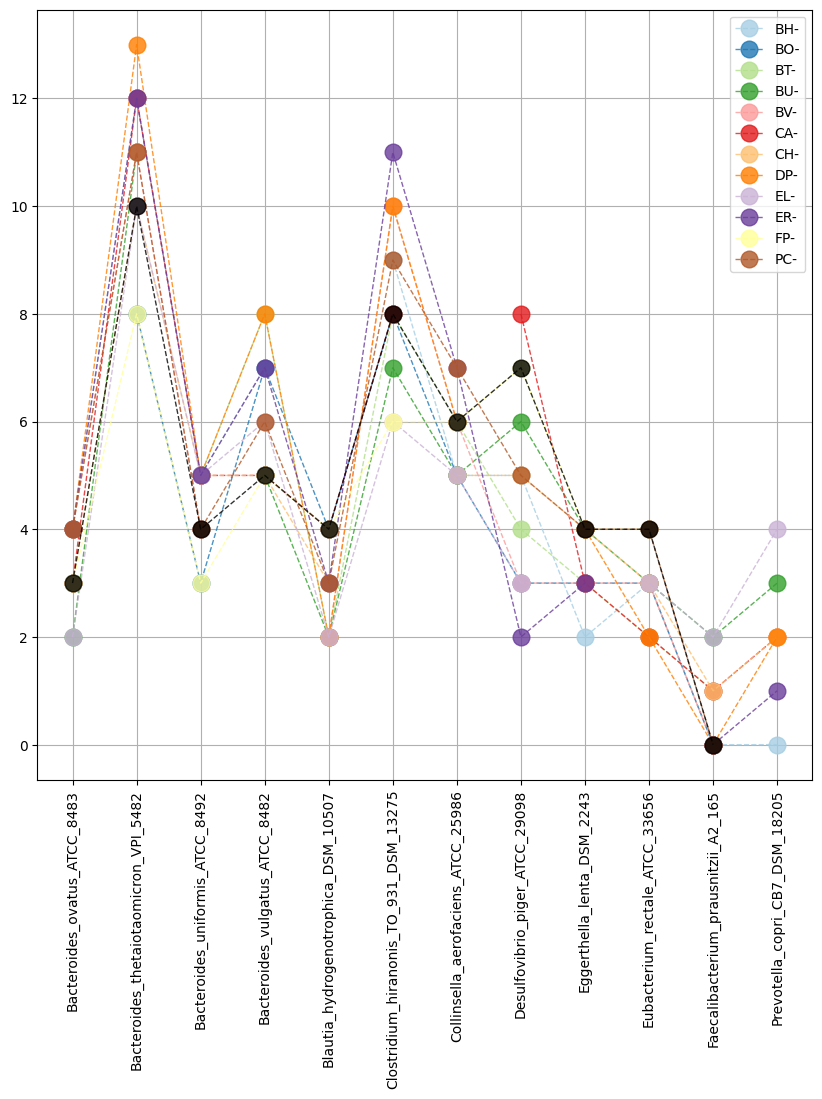

In [341]:

ax = centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired")
centrality_sorted.T["NONE"].plot(ax=ax,color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)

x = centrality_sorted.columns.values
ax.set_xticks(np.arange(len(x)))
labels = ax.set_xticklabels(x,rotation=90)

### Out degree (frequency)

In [342]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

In [343]:
centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,3.046917,1.445500,3.514333,1.872833,NaN,1.633833,1.269833,0.107,3.6865,0.773500,3.942000,0.95750
BO-,NaN,2.215500,2.006500,2.453500,1.341000,1.786000,1.552333,0.322,3.4430,0.921000,3.632833,0.76800
BT-,3.111667,NaN,2.854000,0.897417,1.369333,1.763000,1.650000,0.000,2.6215,0.900000,3.553333,0.59800
BU-,3.478726,1.266500,NaN,1.846250,1.387500,1.798833,1.609000,0.106,0.7870,0.970833,3.382583,1.35900
BV-,2.813533,1.547000,3.029500,NaN,1.241500,1.645500,1.614500,0.000,2.4975,0.750000,4.128500,0.63250
CA-,4.508583,1.349500,3.583250,1.649667,1.350500,2.054667,NaN,0.000,0.7105,0.947367,3.470500,1.48400
CH-,3.625967,1.292500,3.626167,1.900000,1.386500,NaN,0.462333,0.000,0.4245,1.281900,3.088000,1.54650
DP-,4.146967,1.238000,2.879500,2.405500,1.358000,1.681333,0.900167,NaN,2.5145,0.778000,3.743167,0.43825
EL-,3.440500,0.469167,0.476333,2.345833,0.166000,1.265833,1.786500,0.000,NaN,0.978167,3.147917,0.79925
ER-,3.113667,1.016500,3.317833,1.747833,1.445500,1.655000,1.522750,0.101,3.4355,NaN,4.570500,0.61325


In [344]:
#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

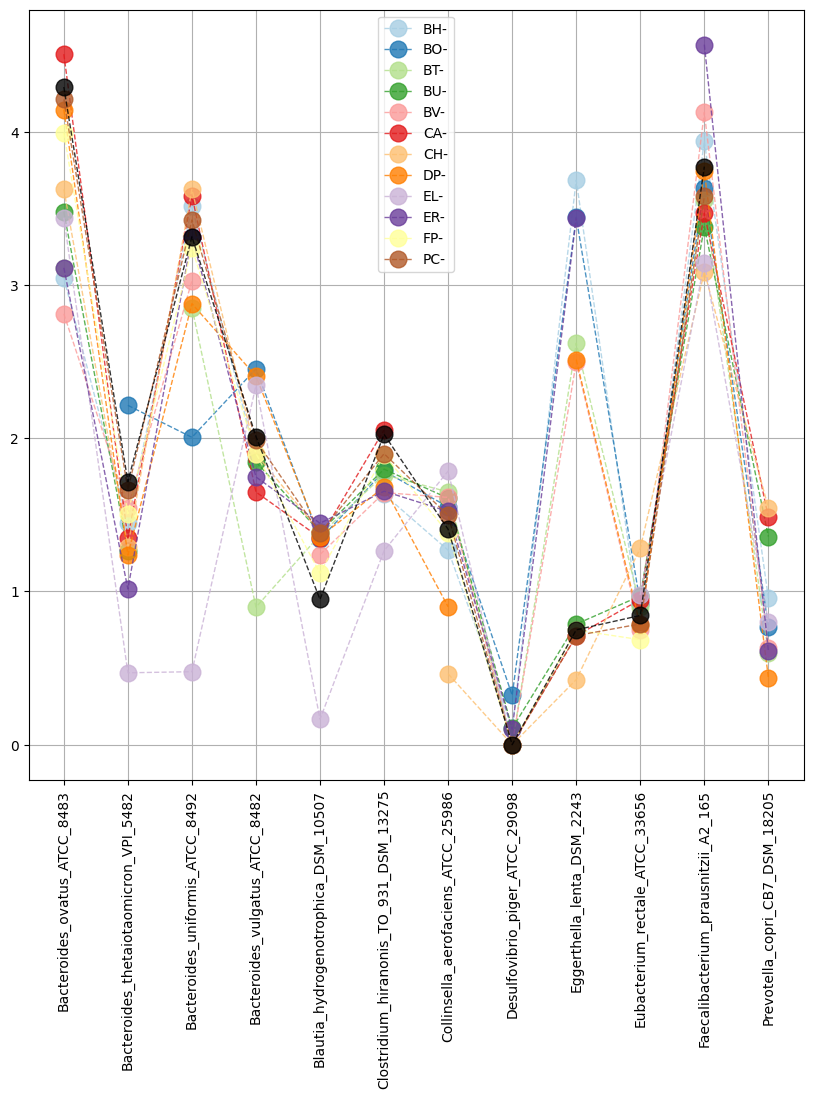

In [345]:

ax = centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired")
centrality_sorted.T["NONE"].plot(ax=ax,color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)

x = centrality_sorted.columns.values
ax.set_xticks(np.arange(len(x)))
labels = ax.set_xticklabels(x,rotation=90)

### In degree (frequency)

In [346]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="in")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

In [347]:
centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,1.092333,4.202500,2.442833,2.654250,NaN,3.280667,1.852167,2.610500,0.928333,1.7070,1.086667,0.392500
BO-,NaN,2.980667,2.238000,2.387667,1.143000,2.695000,1.816833,2.023833,2.165333,1.4995,1.109333,0.382500
BT-,1.401000,NaN,2.615167,2.365833,0.999500,2.823167,1.801833,2.511500,1.942500,1.4300,1.055250,0.372500
BU-,0.791500,3.088643,NaN,1.141667,0.914000,2.167500,1.561000,2.143083,2.500000,1.3955,1.092750,1.196583
BV-,1.381500,3.193200,2.208500,NaN,1.016000,2.894333,1.698500,2.258500,1.961000,1.9445,1.006500,0.337500
CA-,1.207500,3.991750,2.093667,1.960250,0.905667,2.469833,NaN,2.201867,2.588500,1.4410,1.057000,1.191500
CH-,1.126500,3.625300,2.066000,1.738500,0.708000,NaN,1.311500,1.806233,2.619000,1.4430,1.042333,1.148000
DP-,1.174000,3.912200,2.718000,2.376600,0.835000,2.523500,2.078833,NaN,2.317167,1.8345,1.189250,1.124333
EL-,0.899333,2.341125,1.731250,1.294208,1.149500,1.516000,1.332083,1.675500,NaN,1.0535,1.134750,0.748250
ER-,1.442000,4.270833,2.373333,2.495833,0.996000,2.682333,1.841667,2.446167,1.985250,NaN,1.143250,0.862667


In [348]:
#sorter = centrality.max().sort_values().index
sorter = centrality.sort_index(axis=1).columns

centrality_sorted = centrality[sorter]

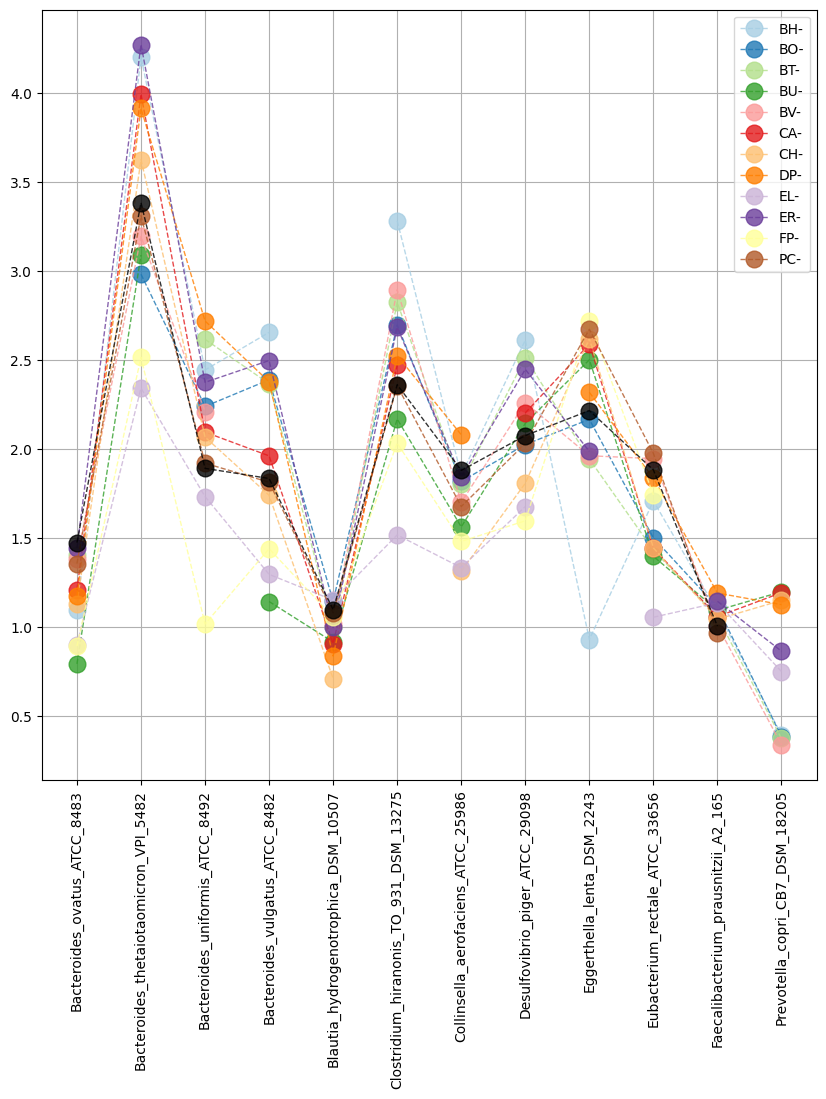

In [349]:

ax = centrality_sorted.loc[(~centrality_sorted.index.str.contains("NONE")),:].T.plot(marker="o",figsize=(10,10),linestyle="--",linewidth=1,markersize=12,alpha=0.8,grid=True,cmap="Paired")
centrality_sorted.T["NONE"].plot(ax=ax,color="black",marker="o",markersize=12,linestyle="--",linewidth=1,alpha=0.8,grid=True)

x = centrality_sorted.columns.values
ax.set_xticks(np.arange(len(x)))
labels = ax.set_xticklabels(x,rotation=90)

In [350]:
centrality_metrics_comm= {}

for comm in results.community.unique():
    results_comm = results[results.community==comm].copy()
    
    network_data = networks.cooperation_network_data(results_comm,metabolomics_mets_only=False,use_count=False,freq_cutoff=0.1)
    centrality_metrics = networks.cooperation_centrality_metrics(network_data,SP_centrality=False,degree_type="out")
    
    centrality_metrics_comm[comm]=centrality_metrics
    

In [351]:
centrality = pd.concat(centrality_metrics_comm)["degree (data)"].unstack()
centrality =centrality.sort_index()
centrality

,Bacteroides_ovatus_ATCC_8483,Bacteroides_thetaiotaomicron_VPI_5482,Bacteroides_uniformis_ATCC_8492,Bacteroides_vulgatus_ATCC_8482,Blautia_hydrogenotrophica_DSM_10507,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,Desulfovibrio_piger_ATCC_29098,Eggerthella_lenta_DSM_2243,Eubacterium_rectale_ATCC_33656,Faecalibacterium_prausnitzii_A2_165,Prevotella_copri_CB7_DSM_18205
BH-,3.046917,1.445500,3.514333,1.872833,NaN,1.633833,1.269833,0.107,3.6865,0.773500,3.942000,0.95750
BO-,NaN,2.215500,2.006500,2.453500,1.341000,1.786000,1.552333,0.322,3.4430,0.921000,3.632833,0.76800
BT-,3.111667,NaN,2.854000,0.897417,1.369333,1.763000,1.650000,0.000,2.6215,0.900000,3.553333,0.59800
BU-,3.478726,1.266500,NaN,1.846250,1.387500,1.798833,1.609000,0.106,0.7870,0.970833,3.382583,1.35900
BV-,2.813533,1.547000,3.029500,NaN,1.241500,1.645500,1.614500,0.000,2.4975,0.750000,4.128500,0.63250
CA-,4.508583,1.349500,3.583250,1.649667,1.350500,2.054667,NaN,0.000,0.7105,0.947367,3.470500,1.48400
CH-,3.625967,1.292500,3.626167,1.900000,1.386500,NaN,0.462333,0.000,0.4245,1.281900,3.088000,1.54650
DP-,4.146967,1.238000,2.879500,2.405500,1.358000,1.681333,0.900167,NaN,2.5145,0.778000,3.743167,0.43825
EL-,3.440500,0.469167,0.476333,2.345833,0.166000,1.265833,1.786500,0.000,NaN,0.978167,3.147917,0.79925
ER-,3.113667,1.016500,3.317833,1.747833,1.445500,1.655000,1.522750,0.101,3.4355,NaN,4.570500,0.61325


In [352]:
import seaborn as sns

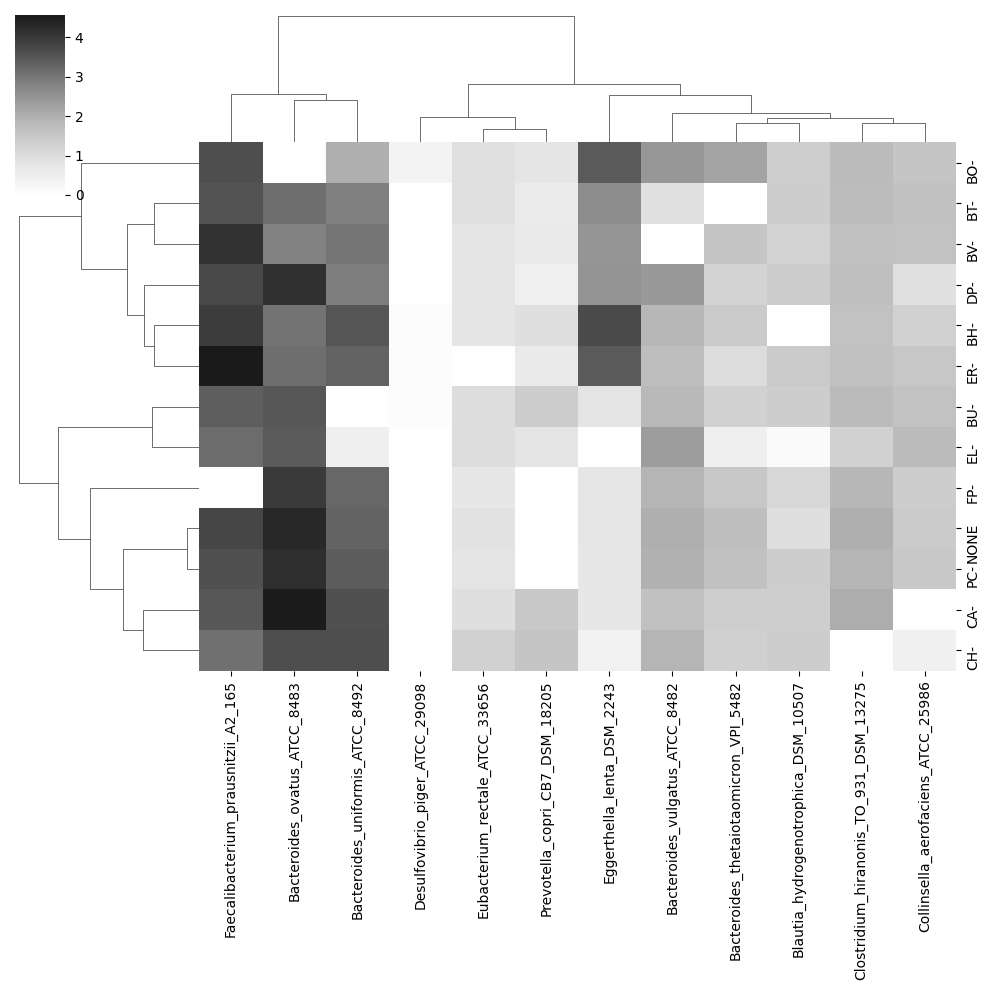

In [353]:
sns.clustermap(centrality.fillna(0),cmap="RdGy",center=0,method="ward")

In [318]:
results_env = results[(results.receiver!="environment")&(results.donor!="environment")]
results_env = results_env[results_env.frequency>0.1]
results_env

,donor,receiver,compound,mass_rate,rate,frequency,community,medium,mass_rate*frequency
44,Bacteroides_uniformis_ATCC_8492,Bacteroides_thetaiotaomicron_VPI_5482,M_fru__91__e__93__,1.081067e-02,0.060007,0.616,ER-,LB_extend,6.659374e-03
57,Bacteroides_uniformis_ATCC_8492,Bacteroides_ovatus_ATCC_8483,M_fru__91__e__93__,9.132545e-03,0.050693,0.571,ER-,LB_extend,5.214683e-03
81,Faecalibacterium_prausnitzii_A2_165,Bacteroides_thetaiotaomicron_VPI_5482,M_fru__91__e__93__,7.732839e-03,0.042923,0.469,ER-,LB_extend,3.626702e-03
91,Faecalibacterium_prausnitzii_A2_165,Bacteroides_ovatus_ATCC_8483,M_fru__91__e__93__,6.639399e-03,0.036854,0.427,ER-,LB_extend,2.835023e-03
146,Bacteroides_vulgatus_ATCC_8482,Faecalibacterium_prausnitzii_A2_165,M_czp__91__e__93__,4.427859e-03,0.014025,0.163,ER-,LB_extend,7.217411e-04
...,...,...,...,...,...,...,...,...,...
26366,Bacteroides_ovatus_ATCC_8483,Eggerthella_lenta_DSM_2243,M_succ__91__e__93__,1.356158e-07,0.000001,0.154,CA-,LB_extend,2.088483e-08
26376,Bacteroides_thetaiotaomicron_VPI_5482,Eggerthella_lenta_DSM_2243,M_succ__91__e__93__,1.278199e-07,0.000001,0.152,CA-,LB_extend,1.942862e-08
26386,Bacteroides_ovatus_ATCC_8483,Clostridium_hiranonis_TO_931_DSM_13275,M_for__91__e__93__,1.182602e-07,0.000003,0.138,CA-,LB_extend,1.631991e-08
26402,Blautia_hydrogenotrophica_DSM_10507,Desulfovibrio_piger_ATCC_29098,M_h2__91__e__93__,9.595242e-08,0.000048,0.125,CA-,LB_extend,1.199405e-08


In [367]:
results_env[["receiver","compound","mass_rate*frequency"]].groupby(["receiver","compound"]).mean().sort_values("mass_rate*frequency",ascending=False).head(30)


mass_rate*frequency
receiver                               compound                                      
Bacteroides_thetaiotaomicron_VPI_5482  M_fru__91__e__93__                    0.005438
Bacteroides_ovatus_ATCC_8483           M_fru__91__e__93__                    0.005216
Bacteroides_vulgatus_ATCC_8482         M_fru__91__e__93__                    0.002017
Bacteroides_ovatus_ATCC_8483           M_lac_D__91__e__93__                  0.001180
Bacteroides_thetaiotaomicron_VPI_5482  M_7ocholate__91__e__93__              0.001144
                                       M_7dhcdchol__91__e__93__              0.001083
Clostridium_hiranonis_TO_931_DSM_13275 M_C02528__91__e__93__                 0.001075
Faecalibacterium_prausnitzii_A2_165    M_fru__91__e__93__                    0.000781
Bacteroides_vulgatus_ATCC_8482         M_7a_czp__91__e__93__                 0.000779
Bacteroides_uniformis_ATCC_8492        M_fru__91__e__93__                    0.000760
Clostridium_hiranonis_TO_931_DSM_13275 M_cholate__91__e__93__                0.000737
Bacteroides_uniformis_ATCC_8492        M_7a_czp__91__e__93__                 0.000708
                                       M_anzp__91__e__93__                   0.000675
Bacteroides_vulgatus_ATCC_8482         M_anzp__91__e__93__                   0.000605
Faecalibacterium_prausnitzii_A2_165    M_czp__91__e__93__                    0.000591
Bacteroides_ovatus_ATCC_8483           M_czp__91__e__93__                    0.000551
                                       M_nzp__91__e__93__                    0.000534
Bacteroides_thetaiotaomicron_VPI_5482  M_anzp__91__e__93__                   0.000524
                                       M_7a_czp__91__e__93__                 0.000501
Faecalibacterium_prausnitzii_A2_165    M_nzp__91__e__93__                    0.000496
Collinsella_aerofaciens_ATCC_25986     M_12dhchol__91__e__93__               0.000477
Eggerthella_lenta_DSM_2243             M_12dhchol__91__e__93__               0.000432
Bacteroides_thetaiotaomicron_VPI_5482  M_gam__91__e__93__                    0.000402
Bacteroides_uniformis_ATCC_8492        M_czp__91__e__93__                    0.000344
                                       M_nzp__91__e__93__                    0.000328
Bacteroides_vulgatus_ATCC_8482         M_sanilamide__91__e__93__             0.000265
Bacteroides_ovatus_ATCC_8483           M_acgam__91__e__93__                  0.000223
                                       M_neopront__91__e__93__               0.000214
Blautia_hydrogenotrophica_DSM_10507    M_fru__91__e__93__                    0.000200
Collinsella_aerofaciens_ATCC_25986     M_fru__91__e__93__                    0.000184

In [324]:
results_env_EL = results_env[results_env.receiver=="Eggerthella_lenta_DSM_2243"]

In [326]:
results_env_EL[["community","donor","compound","frequency","mass_rate*frequency"]].groupby(["community","donor","compound"]).mean().sort_values("frequency",ascending=False).head(30)


frequency  \
community donor                                  compound                             
PC-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           1.000   
BO-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           1.000   
NONE      Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           1.000   
BV-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           1.000   
          Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           1.000   
NONE      Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           1.000   
BU-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           1.000   
FP-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           1.000   
CA-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           1.000   
FP-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           1.000   
BH-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           1.000   
BU-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           0.999   
BO-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           0.999   
BT-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           0.999   
          Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           0.999   
PC-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           0.999   
CH-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           0.998   
ER-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           0.998   
          Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           0.998   
DP-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           0.997   
CH-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__           0.997   
DP-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__           0.997   
NONE      Bacteroides_ovatus_ATCC_8483           M_mqn8__91__e__93__          0.997   
FP-       Bacteroides_ovatus_ATCC_8483           M_mqn8__91__e__93__          0.995   
PC-       Bacteroides_ovatus_ATCC_8483           M_mqn8__91__e__93__          0.994   
CA-       Bacteroides_ovatus_ATCC_8483           M_mqn8__91__e__93__          0.993   
CH-       Bacteroides_ovatus_ATCC_8483           M_mqn8__91__e__93__          0.991   
BU-       Bacteroides_ovatus_ATCC_8483           M_mqn8__91__e__93__          0.941   
CA-       Clostridium_hiranonis_TO_931_DSM_13275 M_12dhchol__91__e__93__      0.506   
NONE      Clostridium_hiranonis_TO_931_DSM_13275 M_12dhchol__91__e__93__      0.386   

                                                                          mass_rate*frequency  
community donor                                  compound                                      
PC-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__              1.791014e-04  
BO-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__              3.081893e-04  
NONE      Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__              3.783528e-06  
BV-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__              2.580053e-04  
          Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__              5.493738e-06  
NONE      Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__              1.953981e-04  
BU-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__              2.800323e-04  
FP-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__              2.177050e-04  
CA-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__              1.384615e-05  
FP-       Blautia_hydrogenotrophica_DSM_10507    M_orn__91__e__93__              1.227704e-06  
BH-       Collinsella_aerofaciens_ATCC_25986     M_orn__91__e__93__              2.493413e-04  
BU-       Blautia_hydrogenotrophica_DSM_1

In [327]:
results_env_EL = results_env[results_env.donor=="Eggerthella_lenta_DSM_2243"]

In [329]:
results_env_EL[["community","receiver","compound","frequency","mass_rate*frequency"]].groupby(["community","receiver","compound"]).mean().sort_values("frequency",ascending=False).head(30)


frequency  \
community receiver                               compound                         
BV-       Bacteroides_thetaiotaomicron_VPI_5482  M_mqn8__91__e__93__      0.998   
          Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__       0.996   
          Bacteroides_thetaiotaomicron_VPI_5482  M_adn__91__e__93__       0.995   
BO-       Bacteroides_vulgatus_ATCC_8482         M_adn__91__e__93__       0.995   
BH-       Bacteroides_thetaiotaomicron_VPI_5482  M_mqn8__91__e__93__      0.995   
          Bacteroides_vulgatus_ATCC_8482         M_mqn8__91__e__93__      0.995   
BT-       Bacteroides_vulgatus_ATCC_8482         M_mqn8__91__e__93__      0.994   
BO-       Bacteroides_vulgatus_ATCC_8482         M_mqn8__91__e__93__      0.994   
BT-       Bacteroides_vulgatus_ATCC_8482         M_adn__91__e__93__       0.992   
BO-       Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__       0.992   
BH-       Bacteroides_vulgatus_ATCC_8482         M_adn__91__e__93__       0.991   
          Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__       0.991   
BO-       Bacteroides_thetaiotaomicron_VPI_5482  M_adn__91__e__93__       0.990   
BH-       Bacteroides_thetaiotaomicron_VPI_5482  M_adn__91__e__93__       0.987   
BT-       Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__       0.986   
BO-       Bacteroides_thetaiotaomicron_VPI_5482  M_mqn8__91__e__93__      0.968   
ER-       Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__       0.925   
          Bacteroides_thetaiotaomicron_VPI_5482  M_adn__91__e__93__       0.925   
          Bacteroides_vulgatus_ATCC_8482         M_adn__91__e__93__       0.925   
                                                 M_mqn8__91__e__93__      0.924   
          Bacteroides_thetaiotaomicron_VPI_5482  M_mqn8__91__e__93__      0.924   
BT-       Bacteroides_uniformis_ATCC_8492        M_adn__91__e__93__       0.643   
BV-       Bacteroides_uniformis_ATCC_8492        M_adn__91__e__93__       0.637   
DP-       Bacteroides_thetaiotaomicron_VPI_5482  M_adn__91__e__93__       0.635   
                                                 M_mqn8__91__e__93__      0.634   
          Bacteroides_vulgatus_ATCC_8482         M_mqn8__91__e__93__      0.634   
                                                 M_adn__91__e__93__       0.633   
          Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__       0.630   
BH-       Bacteroides_uniformis_ATCC_8492        M_adn__91__e__93__       0.625   
BO-       Bacteroides_uniformis_ATCC_8492        M_adn__91__e__93__       0.620   

                                                                      mass_rate*frequency  
community receiver                               compound                                  
BV-       Bacteroides_thetaiotaomicron_VPI_5482  M_mqn8__91__e__93__         3.579396e-05  
          Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__          3.064122e-06  
          Bacteroides_thetaiotaomicron_VPI_5482  M_adn__91__e__93__          1.241898e-05  
BO-       Bacteroides_vulgatus_ATCC_8482         M_adn__91__e__93__          4.254214e-06  
BH-       Bacteroides_thetaiotaomicron_VPI_5482  M_mqn8__91__e__93__         2.845271e-05  
          Bacteroides_vulgatus_ATCC_8482         M_mqn8__91__e__93__         7.409141e-06  
BT-       Bacteroides_vulgatus_ATCC_8482         M_mqn8__91__e__93__         5.291813e-06  
BO-       Bacteroides_vulgatus_ATCC_8482         M_mqn8__91__e__93__         1.417401e-05  
BT-       Bacteroides_vulgatus_ATCC_8482         M_adn__91__e__93__          2.728821e-06  
BO-       Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__          2.886505e-06  
BH-       Bacteroides_vulgatus_ATCC_8482         M_adn__91__e__93__          2.754105e-06  
          Clostridium_hiranonis_TO_931_DSM_13275 M_adn__91__e__93__          2.579179e-06  
BO-       Bacteroides_thetaiotaomicron_VPI_5482  M_adn__91__e__93__          1.215818e-05  
BH-       Bacteroides_thetaiotaom